In [4]:
import os, random, time, copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as T

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.15.0+cpu | Device: cpu


In [5]:
#load dataset and explore  data 
DATA_DIR = "./data"
raw_train = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True,  download=True)
raw_test  = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

class_names = raw_train.classes
print("Classes:", class_names)
print("Train images:", len(raw_train), "| Test images:", len(raw_test))
print("Image size:", raw_train[0][0].size, "| mode:", raw_train[0][0].mode)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train images: 50000 | Test images: 10000
Image size: (32, 32) | mode: RGB


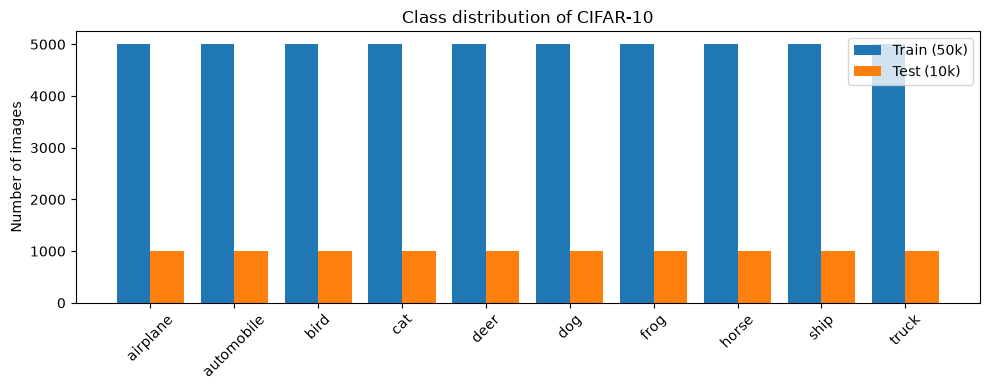

In [6]:
# Class distribution (checks balance)
train_counts = np.bincount(raw_train.targets)
test_counts  = np.bincount(raw_test.targets)

x = np.arange(len(class_names)); w = 0.4
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, train_counts, w, label="Train (50k)")
plt.bar(x + w/2, test_counts,  w, label="Test (10k)")
plt.xticks(x, class_names, rotation=45); plt.ylabel("Number of images")
plt.title("Class distribution of CIFAR-10"); plt.legend(); plt.tight_layout(); plt.show()

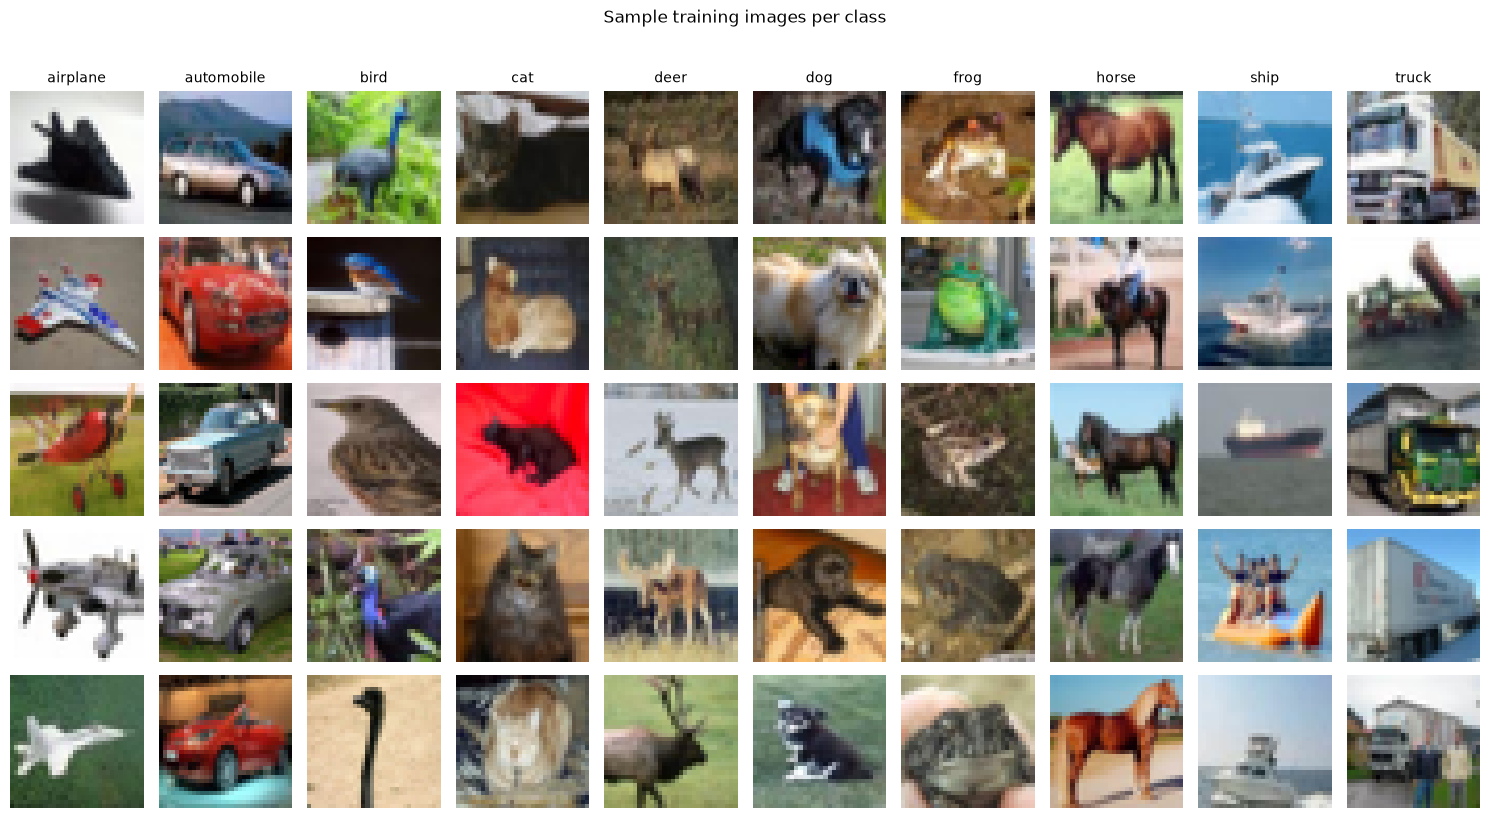

In [7]:
# Sample images from every class
fig, axes = plt.subplots(5, 10, figsize=(15, 8))
for c in range(10):
    idxs = np.where(np.array(raw_train.targets) == c)[0][:5]
    for r, i in enumerate(idxs):
        axes[r, c].imshow(raw_train[i][0]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(class_names[c], fontsize=10)
plt.suptitle("Sample training images per class", y=1.02); plt.tight_layout(); plt.show()

In [8]:
MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([
    T.RandomCrop(32, padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

# Two dataset objects over the same files: one with augmentation, one without
full_train_aug   = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  transform=train_tf)
full_train_noaug = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  transform=eval_tf)
test_set         = torchvision.datasets.CIFAR10(DATA_DIR, train=False, transform=eval_tf)

# Train/validation split (45k / 5k)
indices = np.random.RandomState(SEED).permutation(len(full_train_aug))
train_idx, val_idx = indices[:45000], indices[45000:]
train_set = Subset(full_train_aug,   train_idx)   # augmented
val_set   = Subset(full_train_noaug, val_idx)     # clean

BATCH_SIZE  = 128
NUM_WORKERS = 0   # set to 2 or 4 on Linux/Colab for faster loading; keep 0 on Windows

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
PIN = torch.cuda.is_available()   # only pin memory when a GPU exists

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=PIN)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN)
print(f"Train: {len(train_set)} | Val: {len(val_set)} | Test: {len(test_set)}")
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape, "| Labels shape:", labels.shape)

Train: 45000 | Val: 5000 | Test: 10000
Batch shape: torch.Size([128, 3, 32, 32]) | Labels shape: torch.Size([128])


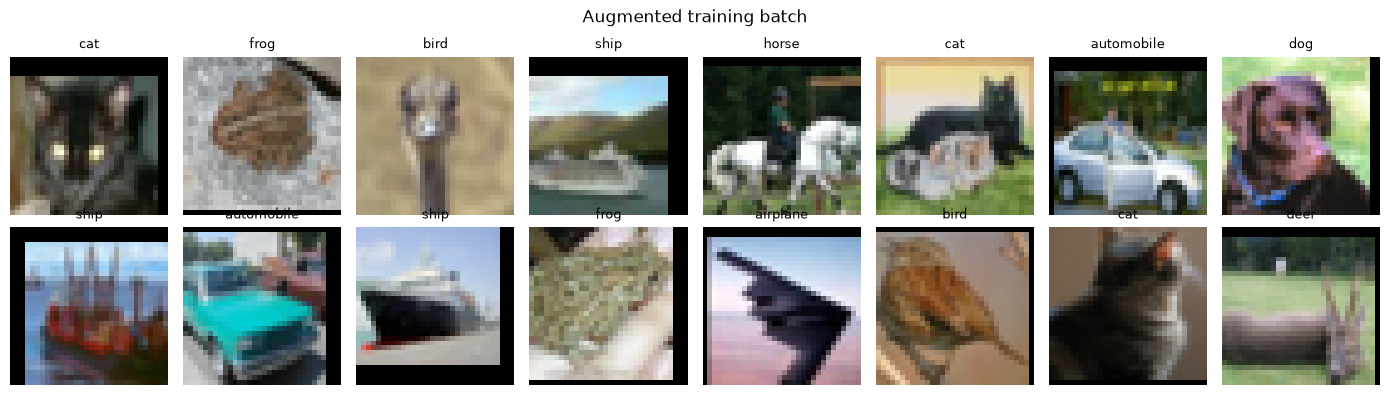

In [9]:
# Visualise augmented training samples (denormalised for display)
def denorm(t):
    m = torch.tensor(MEAN).view(3,1,1); s = torch.tensor(STD).view(3,1,1)
    return (t * s + m).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(denorm(images[i]).permute(1,2,0)); ax.set_title(class_names[labels[i]], fontsize=9); ax.axis("off")
plt.suptitle("Augmented training batch"); plt.tight_layout(); plt.show()

In [10]:
def conv_block(in_ch, out_ch, drop):
    return nn.Sequential(
        nn.Conv2d(in_ch,  out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout2d(drop),
    )

class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3,   32,  0.2),   # 32x32 -> 16x16
            conv_block(32,  64,  0.3),   # 16x16 -> 8x8
            conv_block(64,  128, 0.4),   # 8x8   -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CustomCNN(num_classes=len(class_names)).to(device)
print(model)

CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout2d(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-0

In [11]:
# Detailed summary: try torchinfo, otherwise fall back to a manual layer-by-layer table
try:
    from torchinfo import summary
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torchinfo"])
    from torchinfo import summary

summary(model, input_size=(BATCH_SIZE, 3, 32, 32),
        col_names=("input_size", "output_size", "num_params", "trainable"), depth=4)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
CustomCNN                                [128, 3, 32, 32]          [128, 10]                 --                        True
├─Sequential: 1-1                        [128, 3, 32, 32]          [128, 128, 4, 4]          --                        True
│    └─Sequential: 2-1                   [128, 3, 32, 32]          [128, 32, 16, 16]         --                        True
│    │    └─Conv2d: 3-1                  [128, 3, 32, 32]          [128, 32, 32, 32]         864                       True
│    │    └─BatchNorm2d: 3-2             [128, 32, 32, 32]         [128, 32, 32, 32]         64                        True
│    │    └─ReLU: 3-3                    [128, 32, 32, 32]         [128, 32, 32, 32]         --                        --
│    │    └─Conv2d: 3-4                  [128, 32, 32, 32]         [128, 32, 32, 32]         9,216                     True
│    

In [12]:
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Approx. model size  : {total_params*4/1024**2:.2f} MB (float32)")

Total parameters    : 814,570
Trainable parameters: 814,570
Approx. model size  : 3.11 MB (float32)


In [14]:
# ---- Hyperparameters ----  
EPOCHS        = 40
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
PATIENCE      = 10     # early-stopping patience

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

In [ ]:
def run_epoch(model, loader, train=False):
    # Runs one epoch. If train=True, updates weights; otherwise only evaluates.
    model.train() if train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out  = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct    += (out.argmax(1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
best_acc, best_state, epochs_no_improve = 0.0, None, 0

start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, train=True)
    va_loss, va_acc = run_epoch(model, val_loader,   train=False)
    scheduler.step(va_loss)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    improved = va_acc > best_acc
    if improved:
        best_acc, best_state, epochs_no_improve = va_acc, copy.deepcopy(model.state_dict()), 0
    else:
        epochs_no_improve += 1

    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {history['lr'][-1]:.1e}" + ("  <- best" if improved else ""))

    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}."); break

print(f"\nTraining time: {(time.time()-start)/60:.1f} min | Best val accuracy: {best_acc:.4f}")
model.load_state_dict(best_state)   # restore best weights

Epoch 01/40 | train loss 1.8980 acc 0.3104 | val loss 1.5997 acc 0.4476 | lr 1.0e-03  <- best
Epoch 02/40 | train loss 1.6790 acc 0.4126 | val loss 1.4181 acc 0.5222 | lr 1.0e-03  <- best
Epoch 03/40 | train loss 1.5682 acc 0.4676 | val loss 1.3175 acc 0.5612 | lr 1.0e-03  <- best
Epoch 04/40 | train loss 1.4763 acc 0.5158 | val loss 1.2009 acc 0.6240 | lr 1.0e-03  <- best
Epoch 05/40 | train loss 1.3956 acc 0.5525 | val loss 1.1481 acc 0.6472 | lr 1.0e-03  <- best
Epoch 06/40 | train loss 1.3359 acc 0.5850 | val loss 1.0853 acc 0.6772 | lr 1.0e-03  <- best
Epoch 07/40 | train loss 1.2820 acc 0.6074 | val loss 1.0572 acc 0.6874 | lr 1.0e-03  <- best
Epoch 08/40 | train loss 1.2422 acc 0.6262 | val loss 1.0170 acc 0.7058 | lr 1.0e-03  <- best
Epoch 09/40 | train loss 1.2073 acc 0.6430 | val loss 0.9859 acc 0.7164 | lr 1.0e-03  <- best
Epoch 10/40 | train loss 1.1764 acc 0.6562 | val loss 1.0024 acc 0.7156 | lr 1.0e-03


In [ ]:
#evaluation model and test
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy()); all_labels.extend(y.numpy())
all_preds, all_labels = np.array(all_preds), np.array(all_labels)

test_acc = accuracy_score(all_labels, all_preds)
print(f"Test Accuracy: {test_acc*100:.2f}%\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

In [ ]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix (Test Set)")
plt.tight_layout(); plt.show()

per_class = cm.diagonal() / cm.sum(axis=1)
for n, a in sorted(zip(class_names, per_class), key=lambda t: t[1]):
    print(f"{n:12s} {a*100:5.1f}%")

In [ ]:
# Correct and incorrect predictions on the test set
imgs_all, _ = zip(*[(test_set[i][0], 0) for i in range(len(test_set))])
wrong = np.where(all_preds != all_labels)[0][:10]
right = np.where(all_preds == all_labels)[0][:10]

fig, axes = plt.subplots(2, 10, figsize=(18, 4.5))
for j, i in enumerate(right):
    axes[0, j].imshow(denorm(test_set[i][0]).permute(1,2,0)); axes[0, j].axis("off")
    axes[0, j].set_title(f"T:{class_names[all_labels[i]]}\nP:{class_names[all_preds[i]]}", fontsize=8, color="green")
for j, i in enumerate(wrong):
    axes[1, j].imshow(denorm(test_set[i][0]).permute(1,2,0)); axes[1, j].axis("off")
    axes[1, j].set_title(f"T:{class_names[all_labels[i]]}\nP:{class_names[all_preds[i]]}", fontsize=8, color="red")
plt.suptitle("Top row: correct predictions | Bottom row: misclassifications (T=true, P=predicted)")
plt.tight_layout(); plt.show()

In [ ]:
ep = range(1, len(history["train_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].plot(ep, history["train_loss"], label="Train"); ax[0].plot(ep, history["val_loss"], label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(ep, history["train_acc"], label="Train"); ax[1].plot(ep, history["val_acc"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)

ax[2].plot(ep, history["lr"]); ax[2].set_yscale("log")
ax[2].set_title("Learning rate schedule"); ax[2].set_xlabel("Epoch"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
gap = history["train_acc"][-1] - history["val_acc"][-1]
print(f"Best validation accuracy : {best_acc*100:.2f}%")
print(f"Final test accuracy      : {test_acc*100:.2f}%")
print(f"Train-val accuracy gap   : {gap*100:.2f} pp (last epoch)")
print(f"Epochs trained           : {len(history['train_loss'])}")
print(f"Best class               : {class_names[int(np.argmax(per_class))]} ({per_class.max()*100:.1f}%)")
print(f"Worst class              : {class_names[int(np.argmin(per_class))]} ({per_class.min()*100:.1f}%)")

In [ ]:
SAVE_PATH = "CNN_23-50680-1_weights.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "test_accuracy": test_acc,
    "best_val_accuracy": best_acc,
    "mean": MEAN, "std": STD,
}, SAVE_PATH)
print(f"Saved to {SAVE_PATH} ({os.path.getsize(SAVE_PATH)/1024**2:.2f} MB)")

In [ ]:
# Load the weights into a fresh model and verify it reproduces the test accuracy
ckpt = torch.load(SAVE_PATH, map_location=device)
loaded = CustomCNN(num_classes=len(ckpt["class_names"])).to(device)
loaded.load_state_dict(ckpt["model_state_dict"]); loaded.eval()

correct = 0
with torch.no_grad():
    for x, y in test_loader:
        correct += (loaded(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f"Reloaded model test accuracy: {correct/len(test_set)*100:.2f}% (should match {test_acc*100:.2f}%)")

In [ ]:
# Inference on a single image
idx = 7
img, true_label = test_set[idx]
with torch.no_grad():
    probs = torch.softmax(loaded(img.unsqueeze(0).to(device)), dim=1)[0].cpu()
top = probs.topk(3)
plt.imshow(denorm(img).permute(1,2,0)); plt.axis("off")
plt.title(f"True: {class_names[true_label]} | Pred: {class_names[top.indices[0]]} ({top.values[0]*100:.1f}%)")
plt.show()
for p, i in zip(top.values, top.indices):
    print(f"{class_names[i]:12s} {p*100:.1f}%")

In [ ]:
print("hello")